### 第一步：Json转列表

In [191]:
import re

def parseName(name):
	m = re.search(r'arr_(\w+)', name)
	return (m.group(1)) if m else None

In [192]:
import json

def extractList(config_json, performance_json, arrs):
	### arrs: [None, "block", "layer", "block_layer"]
	### configs: {{"configs"}:{"arr_name"}...{"got"}...}
	### extracted: {{"block": {"model_size_mb": [...], "box_map50": [...]}, ...}}
	extracted = {}

	attibutes = ["model_size_mb", "box_map50", "box_map50_95", "seg_map50", "seg_map50_95"]
	for arr in arrs:
		extracted[arr] = {}
		for k in attibutes:
			extracted[arr][k] = []

	with open(config_json, 'r') as f:
		configs = json.load(f)["configs"]
		print(len(configs))

	with open(performance_json, 'r') as f:
		performances = json.load(f)

    ### original performance
	for performance in performances:
		if not parseName(performance["model_name"]):
			print("aaa")
			for k in attibutes:
				extracted[None][k].append(performance[k])
			continue

    ### q performance
	for config in configs:
		name = parseName(config["arr_name"])
		got = config["got"]
		print(name, config["targetRatio"])
		for performance in performances:
			nodes2quant = performance["nodes_to_quantize"]
						
			if got == nodes2quant:
				print("bbb")
				for k in attibutes:
					extracted[name][k].append(performance[k])
				print(performance["model_name"])
				break
		print("////////////////")

			 
	return extracted

In [193]:
arrs=(None, "block", "layer", "block_layer")
extracted = extractList("configs.json", "performance.json", arrs)
print(extracted)

24
aaa
block 0.1
bbb
q_models\QINT8_yolo26n-seg_r0.1_arr_block.onnx
////////////////
block 0.2
bbb
q_models\QINT8_yolo26n-seg_r0.2_arr_block.onnx
////////////////
block 0.3
bbb
q_models\QINT8_yolo26n-seg_r0.3_arr_block.onnx
////////////////
block 0.4
bbb
q_models\QINT8_yolo26n-seg_r0.5_arr_block.onnx
////////////////
block 0.5
bbb
q_models\QINT8_yolo26n-seg_r0.5_arr_block.onnx
////////////////
block 0.6
bbb
q_models\QINT8_yolo26n-seg_r0.6_arr_block.onnx
////////////////
block 0.7
bbb
q_models\QINT8_yolo26n-seg_r0.7_arr_block.onnx
////////////////
block 0.8
bbb
q_models\QINT8_yolo26n-seg_r0.8_arr_block.onnx
////////////////
layer 0.11042317217616023
bbb
q_models\QINT8_yolo26n-seg_r0.1_arr_block.onnx
////////////////
layer 0.22068482825454938
bbb
q_models\QINT8_yolo26n-seg_r0.2_arr_block.onnx
////////////////
layer 0.29572401086345307
bbb
q_models\QINT8_yolo26n-seg_r0.3_arr_layer.onnx
////////////////
layer 0.48145555914480215
bbb
q_models\QINT8_yolo26n-seg_r0.5_arr_layer.onnx
//////////

### 第二步：绘图

In [194]:
# from matplotlib import pyplot as plt

# def plot(extracted, x_label, metrics, arrs):
#     fig, ax = plt.subplots()
#     for metric in metrics:
#         for arr in arrs:
#             if arr:
#                 pairs = sorted(zip(extracted[arr][x_label], extracted[arr][metric]))
#                 ax.plot([p[0] for p in pairs], [p[1] for p in pairs], marker="o", label=arr)

#     ax.legend()
#     plt.show()


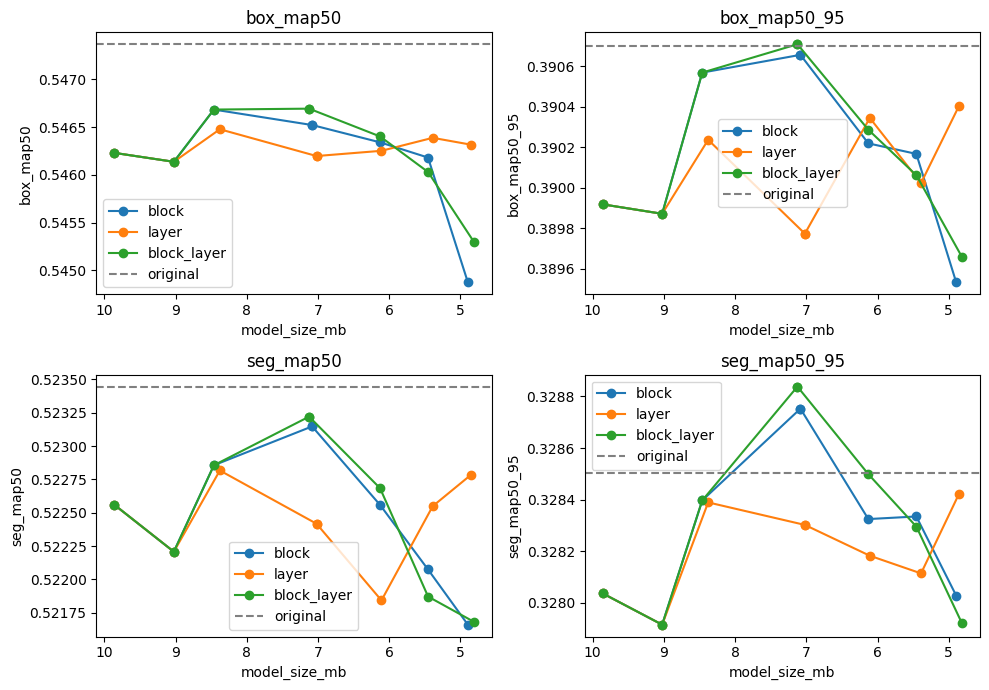

In [195]:
import math
from matplotlib import pyplot as plt

def plot(extracted, x_label, metrics, arrs):
    ncols = 2
    nrows = math.ceil(len(metrics) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 3.5 * nrows), squeeze=False)  # ① 多个子图

    for ax, metric in zip(axes.flat, metrics):        # ② 每个指标对应一个子图
        for arr in arrs:
            if arr:
                pairs = sorted(zip(extracted[arr][x_label], extracted[arr][metric]))
                ax.plot([p[0] for p in pairs], [p[1] for p in pairs], marker="o", label=arr)
        if None in extracted:                         # 原始模型画成基准线
            ax.axhline(extracted[None][metric][0], ls="--", c="gray", label="original")
        ax.set_title(metric)                          # ③ 每个子图单独设置标题和坐标轴
        ax.set_xlabel(x_label)
        ax.set_ylabel(metric)
        ax.invert_xaxis()    
        ax.legend()

    for ax in axes.flat[len(metrics):]:               # 指标数为奇数时，隐藏多余的空子图
        ax.axis("off")

    fig.tight_layout()
    plt.show()

plot(extracted, "model_size_mb",
     ["box_map50", "box_map50_95", "seg_map50", "seg_map50_95"],
     [None, "block", "layer", "block_layer"])

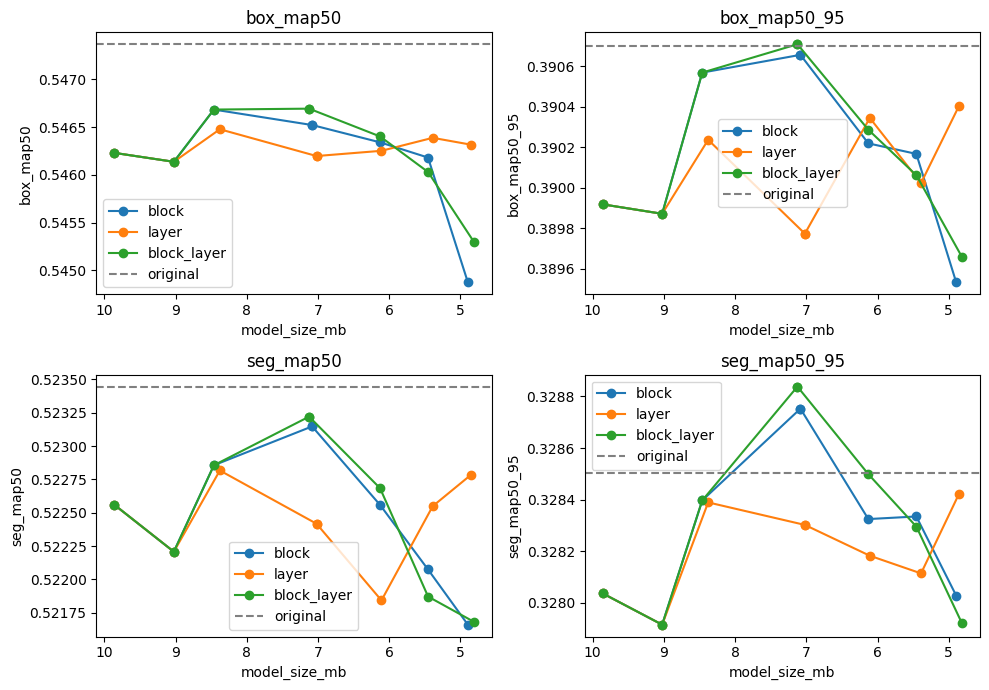

In [196]:
plot(extracted, x_label="model_size_mb", metrics=["box_map50", "box_map50_95", "seg_map50", "seg_map50_95"], arrs=arrs)